# The Mathematics Behind Route Optimization
## Finding Efficient Delivery Routes with Python

### 1. Introduction

Route optimization is the process of finding an efficient route between multiple locations.

In this project, we will explore how mathematics and Python can help find a short delivery route.

We will consider a simple delivery scenario with one warehouse and five delivery locations.

The goal is to visit every delivery location exactly once, return to the warehouse, and minimize the total travel distance.

We will compare three algorithms:
- Random Route
- Nearest Neighbor
- Brute Force

### 2. Mathematical Problem Definition

This project considers a delivery route optimization problem involving one warehouse and five delivery locations.

A courier must start at the warehouse, visit each delivery location exactly once, and return to the warehouse.

The objective is to find the route with the minimum total travel distance.

The problem is based on the following assumptions:

- The warehouse is the starting and ending point.
- Each delivery location must be visited exactly once.
- All locations are represented by points in a two-dimensional coordinate system.
- Distances between locations are measured using Euclidean distance (straight-line distance).
- Real road networks, traffic conditions, and travel times are not considered.

The mathematical goal is to compare valid routes and identify the one with the shortest total distance.


### 3. Coordinates and Vectors

In this project, the warehouse and delivery locations are represented as points in a two-dimensional coordinate system.

Each point is defined by two coordinates:

- **x** — the horizontal position.
- **y** — the vertical position.

A point can be represented as:

$$
P = (x, y)
$$

For example, consider two points:

$$
A = (1, 2), \quad B = (4, 6)
$$

A vector describes the displacement from one point to another.

The vector from point A to point B is calculated by subtracting their coordinates:

$$
\overrightarrow{AB} = (x_B - x_A,\ y_B - y_A)
$$

For our example:

$$
\overrightarrow{AB} = (4 - 1,\ 6 - 2) = (3, 4)
$$

This means that moving from point A to point B requires a displacement of 3 units horizontally and 4 units vertically.

Vectors help us describe the movement between the warehouse and delivery locations.



### 4. Euclidean Distance

Euclidean distance is the straight-line distance between two points in a two-dimensional coordinate system.

It is calculated using the Pythagorean theorem.

For two points:

$$
A = (x_A, y_A), \quad B = (x_B, y_B)
$$

The Euclidean distance is:

$$
d(A,B) = \sqrt{(x_B - x_A)^2 + (y_B - y_A)^2}
$$

For example, consider:

$$
A = (2,1), \quad B = (5,5)
$$

Substituting the coordinates into the formula:

$$
d(A,B) = \sqrt{(5-2)^2 + (5-1)^2}
$$

$$
d(A,B) = \sqrt{3^2 + 4^2}
$$

$$
d(A,B) = \sqrt{9+16} = \sqrt{25} = 5
$$

Therefore, the Euclidean distance between points A and B is 5 units.

Euclidean distance is symmetric, meaning that:

$$
d(A,B) = d(B,A)
$$
Another important property is that the distance from a point to itself is always zero:

$$
d(A,A) = 0
$$

This is because there is no displacement between identical points.

In this project, Euclidean distance will be used to calculate the distances between the warehouse and delivery locations and to determine the total length of each delivery route.

In [1]:
import math

In [2]:
math.sqrt(25)

5.0

In [3]:
point_a = (2, 1)
point_b = (5, 5)

dx = point_b[0] - point_a[0]
dy = point_b[1] - point_a[1]

distance = math.sqrt(dx**2 + dy**2)

print(distance)

5.0


In [4]:
def euclidean_distance(point_a, point_b):
    dx = point_b[0] - point_a[0]
    dy = point_b[1] - point_a[1]

    distance = math.sqrt(dx**2 + dy**2)

    return distance

In [5]:
result = euclidean_distance((2, 1), (5, 5))

print(result)

5.0


In [6]:
distance_ab = euclidean_distance((2, 1), (5, 5))
distance_ba = euclidean_distance((5, 5), (2, 1))

print("Distance A to B:", distance_ab)
print("Distance B to A:", distance_ba)

Distance A to B: 5.0
Distance B to A: 5.0


In [7]:
same_point_distance = euclidean_distance((2, 1), (2, 1))

print("Distance from A to A:", same_point_distance)

Distance from A to A: 0.0



### 5. Delivery Locations and Route Representation

This project considers a simplified delivery scenario with one warehouse and five delivery locations.

All locations are represented by points in a two-dimensional coordinate system. The coordinates are illustrative and do not represent real GPS locations.

The warehouse is the starting and ending point of every delivery route.

| Location | Coordinates | Description |
|----------|-------------|-------------|
| W | (0, 0) | Warehouse |
| A | (2, 3) | Delivery Location 1 |
| B | (5, 1) | Delivery Location 2 |
| C | (6, 5) | Delivery Location 3 |
| D | (3, 7) | Delivery Location 4 |
| E | (8, 3) | Delivery Location 5 |

#### Valid Route

A valid delivery route must satisfy the following conditions:

- Start at the warehouse.
- Visit each of the five delivery locations exactly once.
- Return to the warehouse.

An example of a valid route is:

$$
W \rightarrow A \rightarrow B \rightarrow C \rightarrow D \rightarrow E \rightarrow W
$$

We can represent this route as an ordered sequence of points:

$$
P_0 = W,\quad P_1 = A,\quad P_2 = B,\quad P_3 = C
$$

$$
P_4 = D,\quad P_5 = E,\quad P_6 = W
$$

The route contains six distinct locations, seven positions in the sequence, and six travel segments.

#### Valid Route vs. Optimal Route

A **valid route** satisfies all delivery conditions, but it is not necessarily the shortest route.

An **optimal route** is a valid route with the minimum total travel distance among all possible valid routes.

The objective of this project is to compare different valid delivery routes and identify the shortest one using mathematical calculations and Python algorithms.


In [8]:
locations = {
    "W": (0, 0),
    "A": (2, 3),
    "B": (5, 1),
    "C": (6, 5),
    "D": (3, 7),
    "E": (8, 3)
}

print(locations)

{'W': (0, 0), 'A': (2, 3), 'B': (5, 1), 'C': (6, 5), 'D': (3, 7), 'E': (8, 3)}


In [9]:

route = ["W", "A", "B", "C", "D", "E", "W"]

print(route)


['W', 'A', 'B', 'C', 'D', 'E', 'W']



### 6. Route Length Calculation

The total length of a delivery route is the sum of the Euclidean distances between all consecutive locations in the route.

For the example route:

$$
W \rightarrow A \rightarrow B \rightarrow C \rightarrow D \rightarrow E \rightarrow W
$$

The total route length is:

$$
L = d(W,A) + d(A,B) + d(B,C) + d(C,D) + d(D,E) + d(E,W)
$$

We can also express the total route length using summation notation:

$$
L = \sum_{i=0}^{5} d(P_i, P_{i+1})
$$

Here, $P_0$ is the warehouse at the beginning of the route, and $P_6$ is the warehouse at the end.

The route contains seven positions and six travel segments. Therefore, the summation starts at $i=0$ and ends at $i=5$.

Using the selected coordinates, the distances between consecutive locations are:

| Segment | Exact Distance | Approximate Distance |
|---------|----------------|----------------------|
| W → A | $\sqrt{13}$ | 3.61 |
| A → B | $\sqrt{13}$ | 3.61 |
| B → C | $\sqrt{17}$ | 4.12 |
| C → D | $\sqrt{13}$ | 3.61 |
| D → E | $\sqrt{41}$ | 6.40 |
| E → W | $\sqrt{73}$ | 8.54 |

The exact total distance is:

$$
L = 3\sqrt{13} + \sqrt{17} + \sqrt{41} + \sqrt{73}
$$

Using full precision, the total route length is approximately **29.89 distance units**.

In the Python implementation, distances will be calculated using the existing `euclidean_distance()` function. We will keep full precision during calculations and round only the final result for display.


In [10]:

def calculate_route_length(route, locations):
    total_distance = 0

    for i in range(len(route) - 1):
        point_a = locations[route[i]]
        point_b = locations[route[i + 1]]

        total_distance += euclidean_distance(point_a, point_b)

    return total_distance


In [11]:

total_length = calculate_route_length(route, locations)

print("Total route length:", total_length)
print("Rounded route length:", round(total_length, 2))


Total route length: 29.886887434760006
Rounded route length: 29.89


In [12]:

for i in range(len(route) - 1):
    start = route[i]
    end = route[i + 1]

    segment_distance = euclidean_distance(locations[start], locations[end])

    print(f"{start} -> {end}: {segment_distance:.2f}")


W -> A: 3.61
A -> B: 3.61
B -> C: 4.12
C -> D: 3.61
D -> E: 6.40
E -> W: 8.54


In [14]:
import matplotlib.pyplot as plt

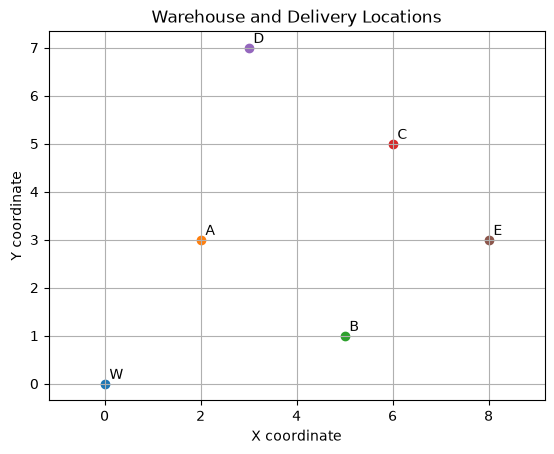

In [15]:

for name, coordinates in locations.items():
    x = coordinates[0]
    y = coordinates[1]

    plt.scatter(x, y)
    plt.text(x + 0.1, y + 0.1, name)

plt.title("Warehouse and Delivery Locations")
plt.xlabel("X coordinate")
plt.ylabel("Y coordinate")
plt.grid(True)
plt.axis("equal")
plt.show()



**Figure 1 — Warehouse and Delivery Locations**

This figure shows the warehouse (W) and five delivery locations (A, B, C, D, E) in a two-dimensional coordinate system.

Each point represents a location with fixed coordinates. The horizontal and vertical axes represent the x and y coordinates.

This visualization illustrates the spatial arrangement of the locations before calculating and comparing delivery routes.


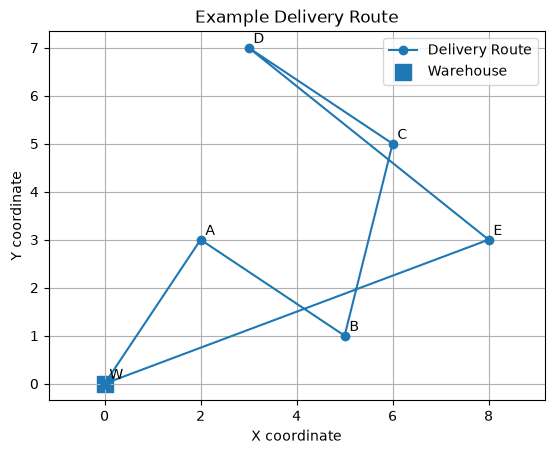

In [19]:
x_values = []
y_values = []

for point_name in route:
    coordinates = locations[point_name]
    x_values.append(coordinates[0])
    y_values.append(coordinates[1])

plt.plot(x_values, y_values, marker="o", label="Delivery Route")

warehouse_x = locations["W"][0]
warehouse_y = locations["W"][1]
plt.scatter(warehouse_x, warehouse_y, s=120, marker="s", label="Warehouse")

for name, coordinates in locations.items():
    x = coordinates[0]
    y = coordinates[1]
    plt.text(x + 0.1, y + 0.1, name)

plt.title("Example Delivery Route")
plt.xlabel("X coordinate")
plt.ylabel("Y coordinate")
plt.grid(True)
plt.axis("equal")
plt.legend()
plt.savefig("../images/example_delivery_route.png", dpi=300, bbox_inches="tight")
plt.show()


**Figure 2 — Example Delivery Route**

This figure illustrates a valid delivery route connecting the warehouse (W) and the five delivery locations (A, B, C, D, E).

The courier starts at the warehouse, visits each delivery location exactly once, and returns to the warehouse following the sequence W → A → B → C → D → E → W.

The lines represent straight-line travel segments calculated using Euclidean distance. The total length of this route is approximately **29.89 distance units**.

Although the route satisfies all delivery conditions, it is not necessarily the optimal route. More efficient routes will be investigated and compared later in the project.
